
Loading sst: data\era5\era5_global\era5_sea_surface_temperature_1940_2025.nc
Loaded shape: (1032, 20, 80)
SST: EOF1 variance = 49.99%
  Original r=+0.966, aligned r=+0.966, flipped=False

Loading msl: data\era5\era5_global\era5_mean_sea_level_pressure_1940_2025.nc
Loaded shape: (1032, 20, 80)
MSLP: EOF1 variance = 38.17%
  Original r=-0.672, aligned r=+0.672, flipped=True

Loading u10: data\era5\era5_global\era5_10m_u_component_of_wind_1940_2025.nc
Loaded shape: (1032, 20, 80)
U10: EOF1 variance = 25.47%
  Original r=+0.670, aligned r=+0.670, flipped=False

Loading v10: data\era5\era5_global\era5_10m_v_component_of_wind_1940_2025.nc
Loaded shape: (1032, 20, 80)
V10: EOF1 variance = 17.49%
  Original r=-0.825, aligned r=+0.825, flipped=True

All four PC series calculated.
              SST      MSLP       U10       V10
1940-01  1.209338 -0.363895 -0.327808 -0.353517
1940-02  1.347368  0.436314 -0.327827  0.842225
1940-03  1.511656  1.388486  1.847747  0.200535
1940-04  1.012212 -0.0244

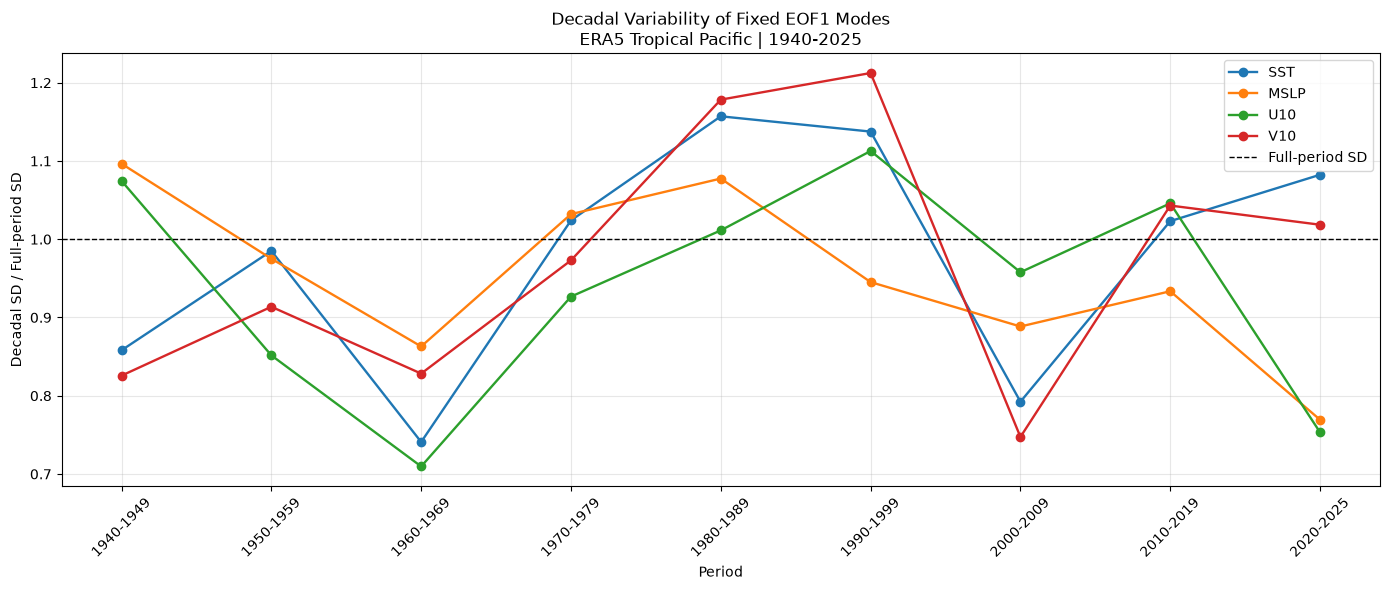

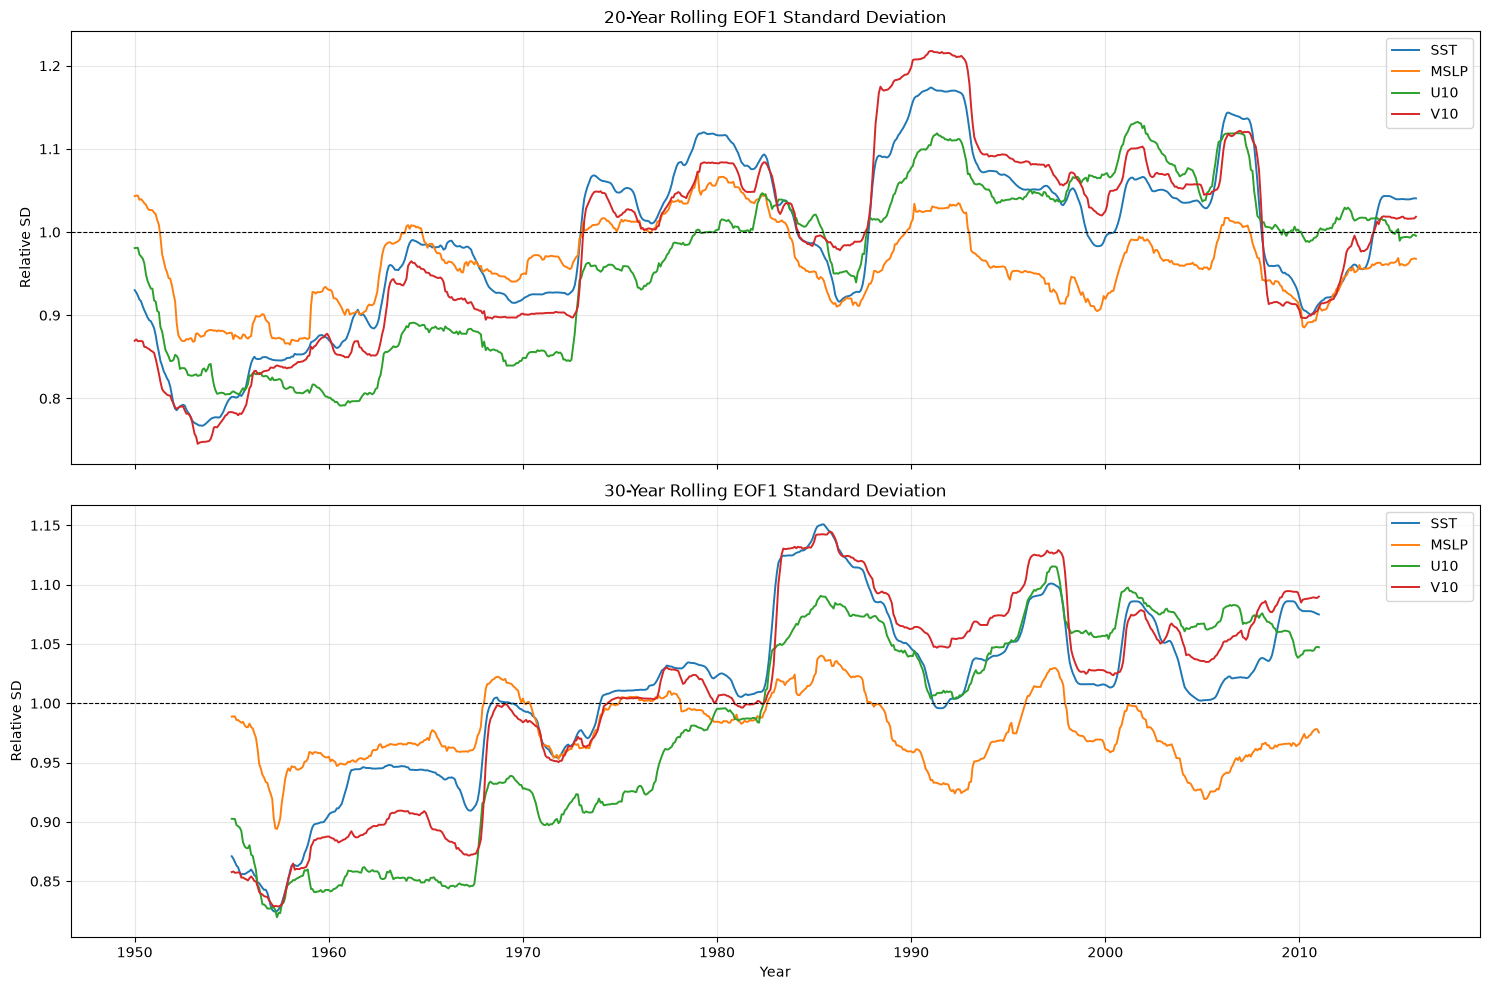

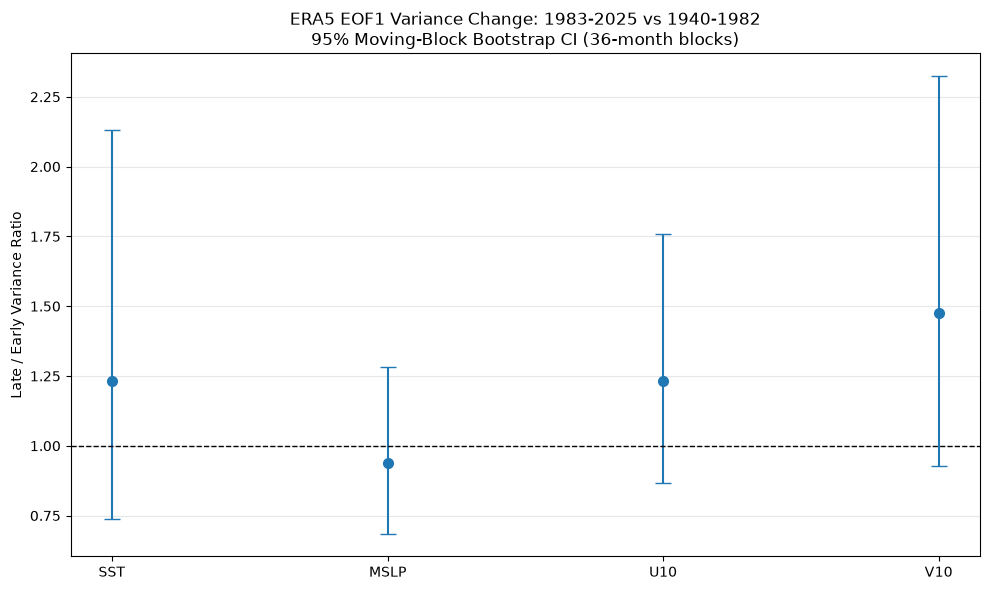


ERA5 ENSO VARIABILITY ANALYSIS COMPLETE

Full-period EOF1 variance explained:
SST: 49.99% | Nino r=0.966
MSLP: 38.17% | Nino r=0.672
U10: 25.47% | Nino r=0.670
V10: 17.49% | Nino r=0.825

Primary early/late results:
          Early SD  Late SD  Variance ratio  CI lower  CI upper  p value
Variable                                                                
SST          0.946    1.051           1.234     0.739     2.133    0.416
MSLP         1.016    0.984           0.937     0.686     1.282    0.682
U10          0.945    1.049           1.233     0.865     1.760    0.223
V10          0.899    1.092           1.475     0.927     2.324    0.148

Outputs:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\derived_data\era5\variability
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_variability


In [1]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import detrend
from sklearn.decomposition import PCA

# ============================================================
# ERA5 ENSO-RELATED VARIABILITY ANALYSIS
# SST, MSLP, U10, V10 | 1940-2025
# Fixed full-period tropical Pacific EOF1
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

LAT_MIN, LAT_MAX = -20, 20
LON_MIN, LON_MAX = 120, 280

COARSEN_FACTOR = 8
N_BOOTSTRAP = 3000
BLOCK_LENGTHS = [24, 36, 60]
PRIMARY_BLOCK = 36
RANDOM_SEED = 42

DATA_DIR = Path("data/era5/era5_global")
INDEX_DIR = Path("derived_data/era5/indices")
OUTPUT_DIR = Path("derived_data/era5/variability")
FIG_DIR = Path("figures/era5_variability")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "SST": (
        "era5_sea_surface_temperature_1940_2025.nc",
        "sst"
    ),
    "MSLP": (
        "era5_mean_sea_level_pressure_1940_2025.nc",
        "msl"
    ),
    "U10": (
        "era5_10m_u_component_of_wind_1940_2025.nc",
        "u10"
    ),
    "V10": (
        "era5_10m_v_component_of_wind_1940_2025.nc",
        "v10"
    ),
}

INDEX_FILE = INDEX_DIR / "era5_nino34_1940_2025.nc"

# ============================================================
# 1. LOAD NINO 3.4 INDEX FOR EOF SIGN ALIGNMENT
# ============================================================

with xr.open_dataset(INDEX_FILE) as ds:
    nino = ds["nino34_detrended"].load()

nino_series = pd.Series(
    nino.values,
    index=pd.to_datetime(nino.time.values).to_period("M")
)

assert not nino_series.index.has_duplicates

# ============================================================
# 2. LOAD TROPICAL PACIFIC FIELD
# ============================================================

def load_field(filename, variable):

    path = DATA_DIR / filename
    print(f"\nLoading {variable}: {path}")

    with xr.open_dataset(
        path,
        engine="netcdf4",
        chunks="auto"
    ) as ds:

        if "valid_time" in ds.dims:
            ds = ds.rename({"valid_time": "time"})

        da = ds[variable]

        units = da.attrs.get("units", "")

        # Sort and select before loading data
        da = da.assign_coords(
            longitude=da.longitude % 360
        ).sortby("longitude").sortby("latitude")

        da = da.sel(
            time=slice(
                f"{START_YEAR}-01-01",
                f"{END_YEAR}-12-31"
            ),
            latitude=slice(LAT_MIN, LAT_MAX),
            longitude=slice(LON_MIN, LON_MAX)
        )

        da = da.coarsen(
            latitude=COARSEN_FACTOR,
            longitude=COARSEN_FACTOR,
            boundary="trim"
        ).mean()

        if variable == "sst":
            if units in ("K", "kelvin", "Kelvin"):
                da = da - 273.15
            elif units not in (
                "degC", "C", "celsius", "degrees_C"
            ):
                raise ValueError(f"Unknown SST units: {units}")

        elif variable == "msl":
            if units == "Pa":
                da = da / 100
            elif units not in ("hPa", "mbar"):
                raise ValueError(f"Unknown MSLP units: {units}")

        da = da.transpose(
            "time", "latitude", "longitude"
        ).compute()

    assert da.sizes["time"] == 1032

    print("Loaded shape:", da.shape)
    return da


# ============================================================
# 3. FULL-PERIOD EOF1 AND PROJECTION
# ============================================================

def calculate_fixed_pc(da, name):

    # Remove seasonal cycle
    climatology = da.groupby("time.month").mean("time")
    anomalies = da.groupby("time.month") - climatology

    nt = anomalies.sizes["time"]
    ny = anomalies.sizes["latitude"]
    nx = anomalies.sizes["longitude"]

    matrix = anomalies.values.reshape(nt, ny * nx)

    valid = np.isfinite(matrix).all(axis=0)

    X = matrix[:, valid].astype(np.float64)

    if X.shape[1] == 0:
        raise ValueError(f"No valid cells for {name}")

    # Full-period detrending
    X = detrend(X, axis=0, type="linear")

    # Square-root area weighting
    lat = anomalies.latitude.values

    lat_weights = np.sqrt(
        np.clip(np.cos(np.deg2rad(lat)), 0, None)
    )

    weights_2d = np.broadcast_to(
        lat_weights[:, None], (ny, nx)
    ).reshape(-1)

    weights = weights_2d[valid]

    positive = weights > 1e-8
    X = X[:, positive]
    weights = weights[positive]

    X_weighted = X * weights

    pca = PCA(n_components=1, svd_solver="full")
    pc = pca.fit_transform(X_weighted)[:, 0]

    # Align time coordinates with Nino 3.4
    months = pd.to_datetime(
        anomalies.time.values
    ).to_period("M")

    pc_series = pd.Series(pc, index=months)

    common = pc_series.index.intersection(
        nino_series.index
    )

    a = pc_series.loc[common].to_numpy()
    b = nino_series.loc[common].to_numpy()

    finite = np.isfinite(a) & np.isfinite(b)

    original_r = np.corrcoef(
        a[finite], b[finite]
    )[0, 1]

    # Approach 3: orient EOF and PC together
    sign = -1 if original_r < 0 else 1

    pc = pc * sign
    eof_weighted = pca.components_[0] * sign

    aligned_r = original_r * sign

    # Full-period standardisation, once only
    pc = (pc - pc.mean()) / pc.std(ddof=1)

    result = pd.Series(
        pc,
        index=months,
        name=name
    )

    print(
        f"{name}: EOF1 variance = "
        f"{pca.explained_variance_ratio_[0]*100:.2f}%"
    )
    print(
        f"  Original r={original_r:+.3f}, "
        f"aligned r={aligned_r:+.3f}, "
        f"flipped={sign == -1}"
    )

    return result, {
        "variance_explained": (
            pca.explained_variance_ratio_[0] * 100
        ),
        "original_r": original_r,
        "aligned_r": aligned_r,
        "flipped": sign == -1,
        "eof_weighted": eof_weighted,
    }


# ============================================================
# 4. CALCULATE ALL FOUR PC TIME SERIES
# ============================================================

pc_series = {}
metadata = {}

for name, (filename, variable) in FILES.items():

    da = load_field(filename, variable)

    series, info = calculate_fixed_pc(da, name)

    pc_series[name] = series
    metadata[name] = info

    del da

pcs = pd.concat(pc_series.values(), axis=1)

assert not pcs.isna().any().any()
assert len(pcs) == 1032

pcs.to_csv(
    OUTPUT_DIR / "fixed_eof1_monthly_pcs.csv"
)

print("\nAll four PC series calculated.")
print(pcs.head())

# ============================================================
# 5. DECADAL STANDARD DEVIATIONS
# ============================================================

decadal_rows = []

for name in FILES:

    for start in range(1940, 2026, 10):

        end = min(start + 9, 2025)

        values = pcs.loc[
            (pcs.index.year >= start) &
            (pcs.index.year <= end),
            name
        ]

        decadal_rows.append({
            "Variable": name,
            "Period": f"{start}-{end}",
            "Months": len(values),
            "Relative SD": values.std(ddof=1),
            "Relative variance": values.var(ddof=1),
        })

decadal_df = pd.DataFrame(decadal_rows)

decadal_df.to_csv(
    OUTPUT_DIR / "decadal_variability.csv",
    index=False
)

# ============================================================
# 6. ROLLING STANDARD DEVIATIONS
# ============================================================

rolling_20 = pcs.rolling(
    window=20 * 12,
    center=True,
    min_periods=20 * 12
).std()

rolling_30 = pcs.rolling(
    window=30 * 12,
    center=True,
    min_periods=30 * 12
).std()

# ============================================================
# 7. MOVING-BLOCK BOOTSTRAP
# ============================================================

def block_sample(x, block, rng):
    """
    Circular moving-block bootstrap.
    Returns a sample of the same length as x.
    """
    x = np.asarray(x, dtype=float)
    n = len(x)

    starts = rng.integers(
        0, n, size=int(np.ceil(n / block))
    )

    indices = np.concatenate([
        (start + np.arange(block)) % n
        for start in starts
    ])[:n]

    return x[indices]


def variance_ratio_test(
    early, late, block, n_bootstrap, seed
):
    """
    1. Bootstrap CI: resample each period separately.
    2. Null test: resample from pooled, separately
       centred early/late data under a common
       stationary-variance approximation.

    The pooled test is exploratory and assumes
    sufficiently similar temporal dependence
    between periods.
    """

    rng = np.random.default_rng(seed)

    early = np.asarray(early, dtype=float)
    late = np.asarray(late, dtype=float)

    early = early[np.isfinite(early)]
    late = late[np.isfinite(late)]

    observed = (
        np.var(late, ddof=1) /
        np.var(early, ddof=1)
    )

    boot_ratios = np.empty(n_bootstrap)
    null_ratios = np.empty(n_bootstrap)

    # Pool separately centred periods for null
    pooled = np.concatenate([
        early - early.mean(),
        late - late.mean()
    ])

    for i in range(n_bootstrap):

        # Confidence interval under observed periods
        e = block_sample(early, block, rng)
        l = block_sample(late, block, rng)

        boot_ratios[i] = (
            np.var(l, ddof=1) /
            np.var(e, ddof=1)
        )

        # Null hypothesis: common distribution
        e0 = block_sample(pooled, block, rng)
        l0 = block_sample(pooled, block, rng)

        # Match original sample lengths
        e0 = e0[:len(early)]
        l0 = l0[:len(late)]

        null_ratios[i] = (
            np.var(l0, ddof=1) /
            np.var(e0, ddof=1)
        )

    ci_low, ci_high = np.quantile(
        boot_ratios, [0.025, 0.975]
    )

    # Two-sided test on log variance ratio
    observed_stat = abs(np.log(observed))
    null_stat = abs(np.log(null_ratios))

    p_value = (
        1 + np.sum(null_stat >= observed_stat)
    ) / (n_bootstrap + 1)

    return observed, ci_low, ci_high, p_value


# ============================================================
# 8. EARLY VS LATE VARIANCE TESTS
# ============================================================

def run_period_tests(
    data,
    early_start,
    early_end,
    late_start,
    late_end,
    label
):

    rows = []

    for name in FILES:

        early = data.loc[
            (data.index.year >= early_start) &
            (data.index.year <= early_end),
            name
        ].to_numpy()

        late = data.loc[
            (data.index.year >= late_start) &
            (data.index.year <= late_end),
            name
        ].to_numpy()

        for block in BLOCK_LENGTHS:

            ratio, low, high, p = variance_ratio_test(
                early,
                late,
                block,
                N_BOOTSTRAP,
                RANDOM_SEED + block
            )

            rows.append({
                "Analysis": label,
                "Variable": name,
                "Block months": block,
                "Early SD": np.std(early, ddof=1),
                "Late SD": np.std(late, ddof=1),
                "Variance ratio": ratio,
                "CI lower": low,
                "CI upper": high,
                "p value": p,
            })

    return pd.DataFrame(rows)


# Primary equal-length comparison
primary_tests = run_period_tests(
    pcs,
    1940, 1982,
    1983, 2025,
    "1940-2025"
)

# Sensitivity: shorter record, near-equal periods
# Fixed EOFs are still fitted over 1940-2025.
sensitivity_tests = run_period_tests(
    pcs,
    1959, 1991,
    1992, 2025,
    "1959-2025"
)

tests = pd.concat(
    [primary_tests, sensitivity_tests],
    ignore_index=True
)

tests.to_csv(
    OUTPUT_DIR / "variance_bootstrap_tests.csv",
    index=False
)

print("\nPRIMARY VARIANCE TESTS (36-MONTH BLOCKS)")
print(
    primary_tests[
        primary_tests["Block months"] == PRIMARY_BLOCK
    ].round(3).to_string(index=False)
)

# ============================================================
# 9. PLOT DECADAL VARIABILITY
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

for name in FILES:

    subset = decadal_df[
        decadal_df["Variable"] == name
    ]

    ax.plot(
        subset["Period"],
        subset["Relative SD"],
        marker="o",
        linewidth=1.7,
        label=name
    )

ax.axhline(
    1,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Full-period SD"
)

ax.set_title(
    "Decadal Variability of Fixed EOF1 Modes\n"
    "ERA5 Tropical Pacific | 1940-2025"
)

ax.set_ylabel(
    "Decadal SD / Full-period SD"
)

ax.set_xlabel("Period")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "decadal_variability.png",
    dpi=200
)
plt.show()

# ============================================================
# 10. PLOT ROLLING VARIABILITY
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 10),
    sharex=True
)

dates = pcs.index.to_timestamp()

for name in FILES:

    axes[0].plot(
        dates,
        rolling_20[name],
        label=name,
        linewidth=1.4
    )

    axes[1].plot(
        dates,
        rolling_30[name],
        label=name,
        linewidth=1.4
    )

for ax, years in zip(axes, [20, 30]):

    ax.axhline(
        1, color="black",
        linestyle="--",
        linewidth=0.8
    )

    ax.set_title(
        f"{years}-Year Rolling EOF1 Standard Deviation"
    )

    ax.set_ylabel("Relative SD")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Year")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "rolling_variability.png",
    dpi=200
)
plt.show()

# ============================================================
# 11. PLOT VARIANCE RATIOS WITH 95% CI
# ============================================================

selected = primary_tests[
    primary_tests["Block months"] == PRIMARY_BLOCK
].set_index("Variable").loc[list(FILES)]

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(selected))

ratios = selected["Variance ratio"].to_numpy()
lower = selected["CI lower"].to_numpy()
upper = selected["CI upper"].to_numpy()

ax.errorbar(
    x,
    ratios,
    yerr=[
        ratios - lower,
        upper - ratios
    ],
    fmt="o",
    capsize=6,
    markersize=7
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xticks(x)
ax.set_xticklabels(selected.index)

ax.set_ylabel("Late / Early Variance Ratio")

ax.set_title(
    "ERA5 EOF1 Variance Change: 1983-2025 vs 1940-1982\n"
    "95% Moving-Block Bootstrap CI (36-month blocks)"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "variance_ratio_confidence_intervals.png",
    dpi=200
)
plt.show()

# ============================================================
# 12. SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("ERA5 ENSO VARIABILITY ANALYSIS COMPLETE")
print("=" * 65)

print("\nFull-period EOF1 variance explained:")

for name, info in metadata.items():
    print(
        f"{name}: "
        f"{info['variance_explained']:.2f}% "
        f"| Nino r={info['aligned_r']:.3f}"
    )

print("\nPrimary early/late results:")

print(
    selected[
        ["Early SD", "Late SD",
         "Variance ratio", "CI lower",
         "CI upper", "p value"]
    ].round(3)
)

print("\nOutputs:")
print(OUTPUT_DIR.resolve())
print(FIG_DIR.resolve())

print("=" * 65)


ERA5 NINO 3.4 VARIABILITY ANALYSIS
Months: 1032
First month: 1940-01
Last month: 2025-12

Early period SD: 0.8354
Late period SD: 0.9153
Variance ratio: 1.2005

Testing 24-month blocks...

Testing 36-month blocks...

Testing 60-month blocks...

BOOTSTRAP RESULTS
 Block months  Early SD  Late SD  Variance ratio  CI lower  CI upper  p value
           24    0.8354   0.9153          1.2005    0.7627    1.9418   0.4431
           36    0.8354   0.9153          1.2005    0.7591    1.9641   0.4499
           60    0.8354   0.9153          1.2005    0.7738    1.9386   0.4371


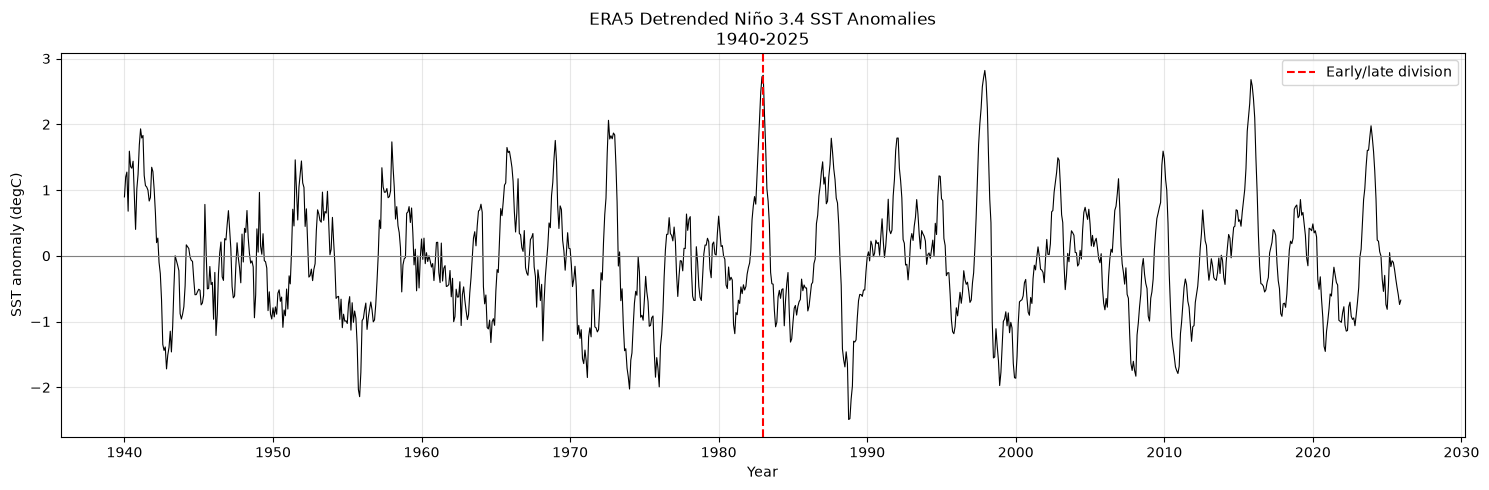

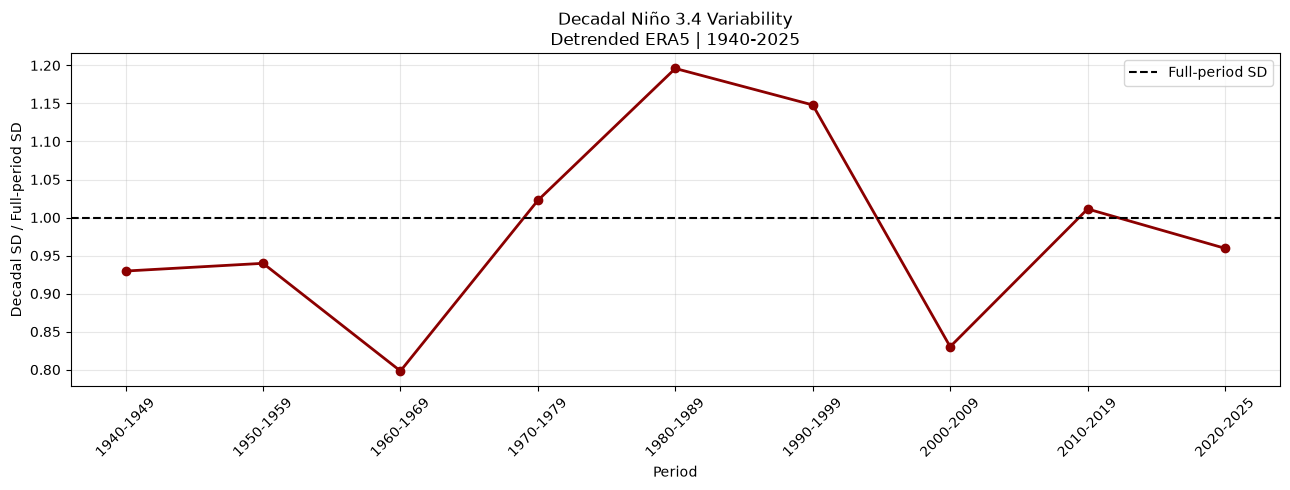

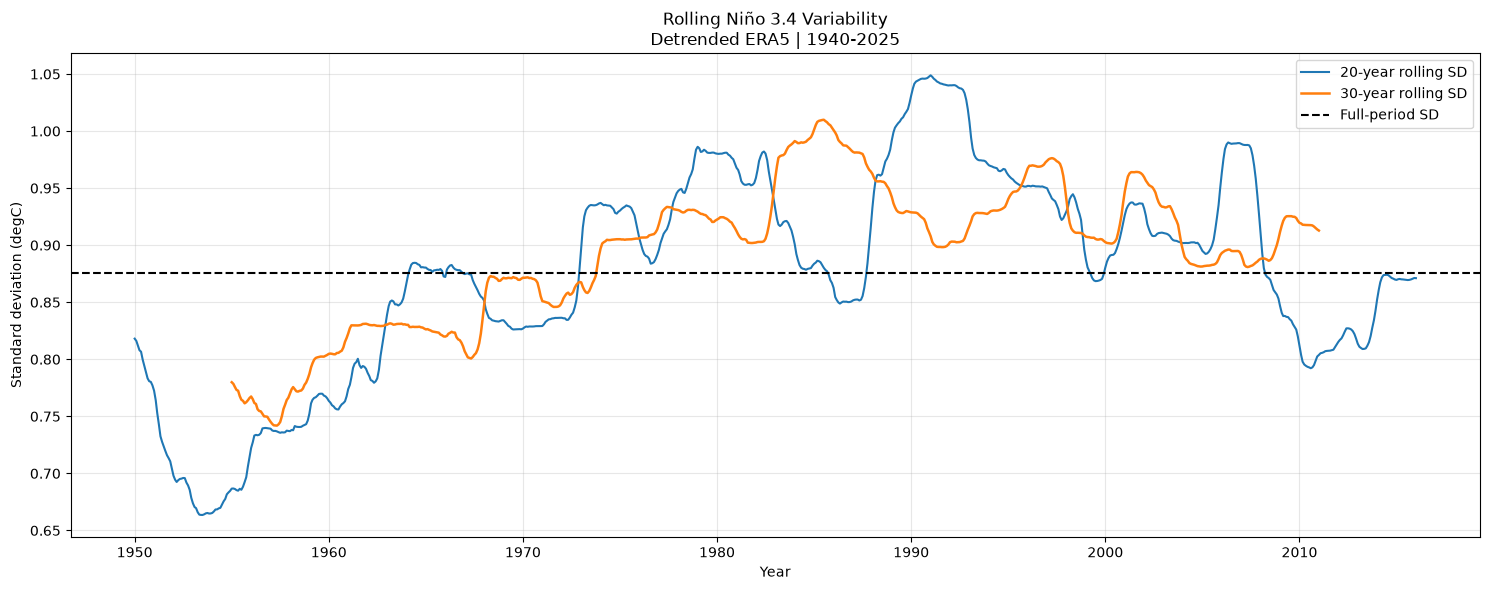

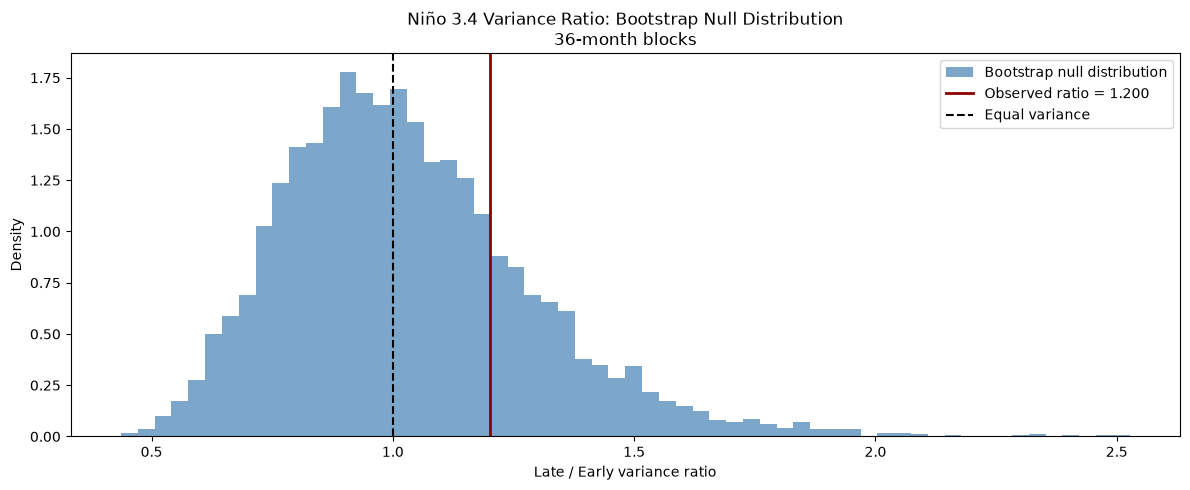


ERA5 NINO 3.4 VARIABILITY TEST SUMMARY
Early SD: 0.8354 degC
Late SD: 0.9153 degC
Variance ratio: 1.2005
95% CI: [0.7591, 1.9641]
Bootstrap p-value: 0.4499

No statistically significant variance difference detected at the 5% level.

Outputs:
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\derived_data\era5\nino34_variability
C:\Users\Adam\Documents\Team Project\CEH_ILESLA\oceans\figures\era5_nino34_variability


In [2]:

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from pathlib import Path

# ============================================================
# ERA5 NINO 3.4 VARIABILITY ANALYSIS
# 1940-2025 | Detrended monthly SST anomalies
# ============================================================

START_YEAR = 1940
END_YEAR = 2025

EARLY_START = 1940
EARLY_END = 1982

LATE_START = 1983
LATE_END = 2025

BLOCK_LENGTHS = [24, 36, 60]
PRIMARY_BLOCK = 36

N_BOOTSTRAP = 5000
RANDOM_SEED = 42

INDEX_FILE = Path(
    "derived_data/era5/indices/"
    "era5_nino34_1940_2025.nc"
)

OUTPUT_DIR = Path(
    "derived_data/era5/nino34_variability"
)

FIG_DIR = Path(
    "figures/era5_nino34_variability"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 1. LOAD NINO 3.4 INDEX
# ============================================================

print("=" * 65)
print("ERA5 NINO 3.4 VARIABILITY ANALYSIS")
print("=" * 65)

with xr.open_dataset(INDEX_FILE) as ds:

    nino = ds["nino34_detrended"].sel(
        time=slice(
            f"{START_YEAR}-01-01",
            f"{END_YEAR}-12-31"
        )
    ).load()

dates = pd.to_datetime(nino.time.values)

series = pd.Series(
    nino.values,
    index=dates.to_period("M"),
    name="Nino34"
).sort_index()

expected = pd.period_range(
    f"{START_YEAR}-01",
    f"{END_YEAR}-12",
    freq="M"
)

assert series.index.equals(expected), (
    "Unexpected or missing monthly observations"
)

assert np.isfinite(series.values).all(), (
    "Niño 3.4 index contains missing values"
)

print("Months:", len(series))
print("First month:", series.index[0])
print("Last month:", series.index[-1])

# ============================================================
# 2. EARLY AND LATE PERIODS
# ============================================================

early = series.loc[
    f"{EARLY_START}-01":f"{EARLY_END}-12"
].to_numpy()

late = series.loc[
    f"{LATE_START}-01":f"{LATE_END}-12"
].to_numpy()

early_std = np.std(early, ddof=1)
late_std = np.std(late, ddof=1)

observed_ratio = (
    np.var(late, ddof=1) /
    np.var(early, ddof=1)
)

print("\nEarly period SD:", round(early_std, 4))
print("Late period SD:", round(late_std, 4))
print("Variance ratio:", round(observed_ratio, 4))

# ============================================================
# 3. CIRCULAR MOVING-BLOCK BOOTSTRAP
# ============================================================

def block_sample(x, block, rng, size=None):

    x = np.asarray(x, dtype=float)

    n = len(x)

    if size is None:
        size = n

    n_blocks = int(np.ceil(size / block))

    starts = rng.integers(
        0, n, size=n_blocks
    )

    indices = (
        starts[:, None] +
        np.arange(block)[None, :]
    ) % n

    return x[indices.ravel()[:size]]


def variance_ratio_test(
    early,
    late,
    block,
    n_bootstrap=5000,
    seed=42
):

    rng = np.random.default_rng(seed)

    n_early = len(early)
    n_late = len(late)

    observed = (
        np.var(late, ddof=1) /
        np.var(early, ddof=1)
    )

    bootstrap_ratios = np.empty(n_bootstrap)
    null_ratios = np.empty(n_bootstrap)

    # Pool centred observations for approximate null
    pooled = np.concatenate([
        early - np.mean(early),
        late - np.mean(late)
    ])

    for i in range(n_bootstrap):

        # Bootstrap confidence interval:
        # resample each period independently
        e = block_sample(
            early, block, rng, n_early
        )

        l = block_sample(
            late, block, rng, n_late
        )

        bootstrap_ratios[i] = (
            np.var(l, ddof=1) /
            np.var(e, ddof=1)
        )

        # Null distribution:
        # both samples from pooled process
        e0 = block_sample(
            pooled, block, rng, n_early
        )

        l0 = block_sample(
            pooled, block, rng, n_late
        )

        null_ratios[i] = (
            np.var(l0, ddof=1) /
            np.var(e0, ddof=1)
        )

    ci_low, ci_high = np.quantile(
        bootstrap_ratios,
        [0.025, 0.975]
    )

    # Two-sided log variance-ratio test
    observed_stat = abs(np.log(observed))

    null_stat = np.abs(
        np.log(null_ratios)
    )

    p_value = (
        1 + np.sum(null_stat >= observed_stat)
    ) / (n_bootstrap + 1)

    return {
        "observed": observed,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_value": p_value,
        "bootstrap_ratios": bootstrap_ratios,
        "null_ratios": null_ratios,
    }

# ============================================================
# 4. RUN BOOTSTRAP SENSITIVITY TESTS
# ============================================================

results = {}
rows = []

for block in BLOCK_LENGTHS:

    print(f"\nTesting {block}-month blocks...")

    result = variance_ratio_test(
        early,
        late,
        block,
        N_BOOTSTRAP,
        RANDOM_SEED + block
    )

    results[block] = result

    rows.append({
        "Block months": block,
        "Early SD": early_std,
        "Late SD": late_std,
        "Variance ratio": result["observed"],
        "CI lower": result["ci_low"],
        "CI upper": result["ci_high"],
        "p value": result["p_value"],
    })

summary = pd.DataFrame(rows)

print("\n" + "=" * 65)
print("BOOTSTRAP RESULTS")
print("=" * 65)

print(
    summary.round(4).to_string(index=False)
)

summary.to_csv(
    OUTPUT_DIR / "nino34_bootstrap_results.csv",
    index=False
)

# ============================================================
# 5. DECADAL VARIABILITY
# ============================================================

full_std = series.std(ddof=1)

decadal_rows = []

for start in range(START_YEAR, END_YEAR + 1, 10):

    end = min(start + 9, END_YEAR)

    subset = series.loc[
        f"{start}-01":f"{end}-12"
    ]

    decadal_rows.append({
        "Period": f"{start}-{end}",
        "Months": len(subset),
        "SD (degC)": subset.std(ddof=1),
        "Variance (degC2)": subset.var(ddof=1),
        "Relative SD": (
            subset.std(ddof=1) / full_std
        ),
    })

decadal_df = pd.DataFrame(decadal_rows)

decadal_df.to_csv(
    OUTPUT_DIR / "nino34_decadal_variability.csv",
    index=False
)

# ============================================================
# 6. ROLLING STANDARD DEVIATIONS
# ============================================================

rolling_20 = series.rolling(
    20 * 12,
    center=True,
    min_periods=20 * 12
).std()

rolling_30 = series.rolling(
    30 * 12,
    center=True,
    min_periods=30 * 12
).std()

# ============================================================
# 7. PLOT MONTHLY NINO 3.4 INDEX
# ============================================================

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    series.index.to_timestamp(),
    series.values,
    color="black",
    linewidth=0.8
)

ax.axhline(
    0, color="grey", linewidth=0.8
)

ax.axvline(
    pd.Timestamp("1983-01-01"),
    color="red",
    linestyle="--",
    label="Early/late division"
)

ax.set_title(
    "ERA5 Detrended Niño 3.4 SST Anomalies\n"
    "1940-2025"
)

ax.set_xlabel("Year")
ax.set_ylabel("SST anomaly (degC)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "nino34_detrended_timeseries.png",
    dpi=200
)
plt.show()

# ============================================================
# 8. PLOT DECADAL STANDARD DEVIATION
# ============================================================

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    decadal_df["Period"],
    decadal_df["Relative SD"],
    marker="o",
    linewidth=2,
    color="darkred"
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    label="Full-period SD"
)

ax.set_title(
    "Decadal Niño 3.4 Variability\n"
    "Detrended ERA5 | 1940-2025"
)

ax.set_ylabel(
    "Decadal SD / Full-period SD"
)

ax.set_xlabel("Period")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "nino34_decadal_variability.png",
    dpi=200
)
plt.show()

# ============================================================
# 9. PLOT ROLLING STANDARD DEVIATIONS
# ============================================================

fig, ax = plt.subplots(figsize=(15, 6))

dates = series.index.to_timestamp()

ax.plot(
    dates,
    rolling_20,
    label="20-year rolling SD",
    linewidth=1.5
)

ax.plot(
    dates,
    rolling_30,
    label="30-year rolling SD",
    linewidth=1.8
)

ax.axhline(
    full_std,
    color="black",
    linestyle="--",
    label="Full-period SD"
)

ax.set_title(
    "Rolling Niño 3.4 Variability\n"
    "Detrended ERA5 | 1940-2025"
)

ax.set_ylabel("Standard deviation (degC)")
ax.set_xlabel("Year")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "nino34_rolling_variability.png",
    dpi=200
)
plt.show()

# ============================================================
# 10. PLOT BOOTSTRAP NULL DISTRIBUTION
# ============================================================

primary = results[PRIMARY_BLOCK]

fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(
    primary["null_ratios"],
    bins=60,
    density=True,
    color="steelblue",
    alpha=0.7,
    label="Bootstrap null distribution"
)

ax.axvline(
    observed_ratio,
    color="darkred",
    linewidth=2,
    label=f"Observed ratio = {observed_ratio:.3f}"
)

ax.axvline(
    1,
    color="black",
    linestyle="--",
    label="Equal variance"
)

ax.set_title(
    "Niño 3.4 Variance Ratio: Bootstrap Null Distribution\n"
    "36-month blocks"
)

ax.set_xlabel("Late / Early variance ratio")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.savefig(
    FIG_DIR / "nino34_bootstrap_null_distribution.png",
    dpi=200
)
plt.show()

# ============================================================
# 11. FINAL SUMMARY
# ============================================================

primary_row = summary[
    summary["Block months"] == PRIMARY_BLOCK
].iloc[0]

print("\n" + "=" * 65)
print("ERA5 NINO 3.4 VARIABILITY TEST SUMMARY")
print("=" * 65)

print(f"Early SD: {early_std:.4f} degC")
print(f"Late SD: {late_std:.4f} degC")

print(
    f"Variance ratio: "
    f"{observed_ratio:.4f}"
)

print(
    f"95% CI: "
    f"[{primary_row['CI lower']:.4f}, "
    f"{primary_row['CI upper']:.4f}]"
)

print(
    f"Bootstrap p-value: "
    f"{primary_row['p value']:.4f}"
)

if primary_row["p value"] < 0.05:
    print(
        "\nStatistically significant variance "
        "difference at the 5% level "
        "under the bootstrap null model."
    )
else:
    print(
        "\nNo statistically significant variance "
        "difference detected at the 5% level."
    )

print("\nOutputs:")
print(OUTPUT_DIR.resolve())
print(FIG_DIR.resolve())

print("=" * 65)
